Полезные ссылки
Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-klassy-linear-i-module

Телеграм-канал: https://t.me/machine_learning_selfedu

PyTorch: https://pytorch.org/tutorials/

In [51]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from random import randint

перемножение матрицы весов на входные признаки и прибавление к этому биаса может быть заменено одним классов torch.nn.Linear (без функции активации)

In [32]:
layer1 = nn.Linear(in_features=3, out_features=2)
layer2 = nn.Linear(in_features=2, out_features=1)

In [33]:
# веса на этом слое берутся из равномерного распределения на интервале +-1/sqrt(n), где n - размер выборки
layer1.weight

Parameter containing:
tensor([[ 0.3434,  0.1744, -0.3636],
        [ 0.5658,  0.3049,  0.1576]], requires_grad=True)

In [34]:
# смещения на этом слое
layer1.bias

Parameter containing:
tensor([-0.2291,  0.1074], requires_grad=True)

У класса Linear есть метод forward, реализующий матричное перемножение. убедимся, что перемножение вручную и при помощи этого метода дают один результат

In [35]:
x = torch.tensor([1,2,3], dtype=torch.float32)

In [36]:
x @ layer1.weight.T + layer1.bias

tensor([-0.6276,  1.7556], grad_fn=<AddBackward0>)

In [37]:
layer1.forward(x)

tensor([-0.6276,  1.7556], grad_fn=<ViewBackward0>)

In [39]:
def forward(inp, l1: nn.Linear, l2: nn.Linear):
    u1 = l1.forward(inp)
    s1 = F.tanh(u1)

    u2 = l2.forward(s1)
    s2 = F.tanh(u2)

    return s2

In [40]:
forward(x, layer1, layer2)

tensor([0.2424], grad_fn=<TanhBackward0>)

Но объединять такую логику внутри функции менее удобно, чем внутри класса

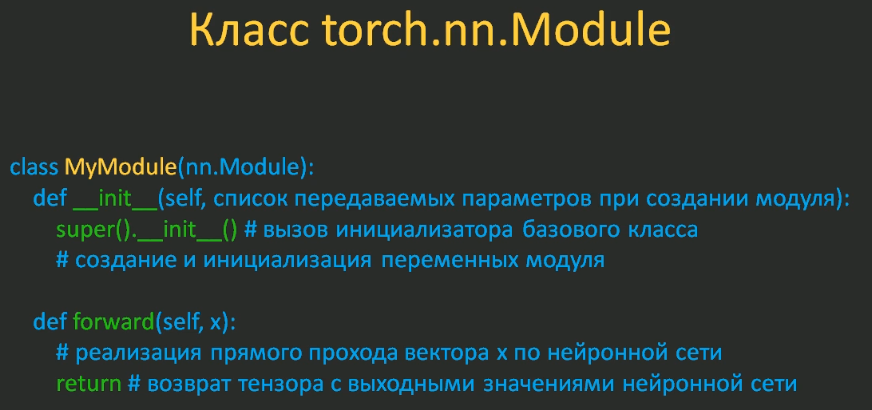

In [44]:
class MyNet(nn.Module):
    def __init__(self, input_dim, num_hidden, output_dim):
        super().__init__()
        self.layer1 = nn.Linear(input_dim, num_hidden)
        self.layer2 = nn.Linear(num_hidden, output_dim)

    def forward(self, x):
        x = self.layer1(x)
        x = F.tanh(x)
        x = self.layer2(x)
        x = F.tanh(x)
        return x

In [53]:
model = MyNet(3, 2, 1)
model

MyNet(
  (layer1): Linear(in_features=3, out_features=2, bias=True)
  (layer2): Linear(in_features=2, out_features=1, bias=True)
)

можно получить из модели параметры (чтобы веротно их потом передать в оптимизатор)

In [54]:
print(list(model.parameters()))

[Parameter containing:
tensor([[-0.4707,  0.5695,  0.4565],
        [ 0.2321,  0.2638, -0.4569]], requires_grad=True), Parameter containing:
tensor([ 0.4452, -0.1887], requires_grad=True), Parameter containing:
tensor([[ 0.4894, -0.6959]], requires_grad=True), Parameter containing:
tensor([-0.1334], requires_grad=True)]


Теперь обучаем модель

In [55]:
x_train = torch.FloatTensor([(-1, -1, -1), (-1, -1, 1), (-1, 1, -1), (-1, 1, 1),
                            (1, -1, -1), (1, -1, 1), (1, 1, -1), (1, 1, 1)])
y_train = torch.FloatTensor([-1, 1, -1, 1, -1, 1, -1, -1])
total = len(y_train)


optimizer = optim.RMSprop(params=model.parameters(), lr=0.01)
loss_func = torch.nn.MSELoss()

# переводим модель в режим обучения
model.train()

for _ in range(1000):
    k = randint(0, total-1)
    y = model(x_train[k])
    loss = loss_func(y, y_train[k])

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


In [63]:
# КОММЕНТ:
# Информация уже давно устарела.
# Сейчас используют связку для инференса ->
# model.eval()
# with torch.inference_mode(): ...
for x, d in zip(x_train, y_train):
    with torch.no_grad(): # на время инференса градиенты отключают
        y = model(x)
        print(f"Выходное значение НС: {y.data.item():.2f} => {d}")

    

Выходное значение НС: -0.99 => -1.0
Выходное значение НС: 1.00 => 1.0
Выходное значение НС: -1.00 => -1.0
Выходное значение НС: 0.98 => 1.0
Выходное значение НС: -1.00 => -1.0
Выходное значение НС: 0.98 => 1.0
Выходное значение НС: -1.00 => -1.0
Выходное значение НС: -0.99 => -1.0
